In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F

from IPython.display import clear_output
from net.common import savefig
warnings.filterwarnings("ignore")
clear_output()

In [2]:
a = torch.FloatTensor([1,2,3]).requires_grad_()
b = a * 2
captured = [None]
b.register_hook(lambda g: captured.__setitem__(0, g.detach().clone()))
c = b.sum()
c.backward()
print(captured)

[tensor([1., 1., 1.])]


In [3]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
}
rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ob_size = 5
act_size = 3
print(f"ob_size: {ob_size}, act_size: {act_size}"   )

ob_size: 5, act_size: 3


In [4]:
# task_ids = ["go", "anti", "dlygo", "dlyanti"]
task_ids = ["go", "dlygo", "anti", "dlyanti"]
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]

In [5]:
import pickle
model_names = ['eisep', 'simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# model_names = ['eisep', 'simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# model_names = ['eisep', 'simple']
# legend_names = ['EISep', 'Simple', 'EntryEI', 'Fixed-EISep', 'Fixed-EntryEI',  'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam']
legend_names = ['EISep', 'Simple', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# legend_names = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# legend_names = ['EISep', 'Simple']
lrs = np.array([0.5, 1e-1, 5e-2, 1e-2, 5e-3, 1e-3, 5e-4, 1e-4])
n_seed = 5
epochs = 3000
hidden_size = 64
len_multilr_envs = 20
n_lr = len(lrs)
test_acc = np.zeros((len(model_names), n_lr, n_seed, len_multilr_envs))
net_state_dicts = []
# colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
# colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00', '#56B4E9']
colors = ['C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', '#E69F00', '#56B4E9']

for i, model_name in enumerate(model_names):
    print(i)
    path = f'./result/multitask/multilr_{model_name}_performance.pkl'
    with open(path, 'rb') as f:
        info = pickle.load(f)
    test_acc[i] = info['performance']
# print(env_names)
test_acc_flatten = test_acc.reshape(len(model_names), len(lrs), -1)
mean_acc = np.mean(test_acc_flatten, axis=-1)
best_lr_idx = np.argmax(mean_acc, axis=-1)
best_lrs = lrs[best_lr_idx]
print(f"Best lrs: {best_lrs}")
best_lr_dict = {model_name: float(best_lr) for model_name, best_lr in zip(model_names, best_lrs)}
print(best_lr_dict)

0
1
2
3
4
5
6
7
8
9
10
11
Best lrs: [0.01   0.005  0.1    0.0005 0.1    0.005  0.001  0.01   0.01   0.01
 0.01   0.01  ]
{'eisep': 0.01, 'simple': 0.005, 'dann_sgd': 0.1, 'dann_adam': 0.0005, 'colei_sgd': 0.1, 'colei_adam': 0.005, 'dbpn': 0.001, 'absolute_eisep': 0.01, 'fixed_eisep': 0.01, 'entryei': 0.01, 'eisep_init_ColEI': 0.01, 'eisep_init_DBPN': 0.01}


In [6]:
import pickle as pkl
import numpy as np
import os
model_names = ['eisep', 'simple']
legend_names = ['EISep', 'Simple']
model_colors = ['C1', 'C0']

# model_names = ['eisep', 'simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn']
# legend_names = ['EISep', 'Simple', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
# model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']

# model_names = ['eisep', 'simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# legend_names = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00', '#009E73']

lrs = [best_lr_dict[model_name] for model_name in model_names]
# paths = [f'./result/continual_learning_reweight/hidden_64/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]
paths = [f'./result/continual_learning_gradient_alignment_reorder_old/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]

for i in range(len(paths)):
    print(paths[i])
infos = [pkl.load(open(path, 'rb')) for path in paths]
test_perfs = [info['test_perf_all'] for info in infos]
print('EISep:')
for k,v in infos[0].items():
    print(k, np.array(v).shape)
print('Simple:')
for k,v in infos[1].items():
    print(k, np.array(v).shape)

./result/continual_learning_gradient_alignment_reorder_old/lr0.01_eisep_info.pkl
./result/continual_learning_gradient_alignment_reorder_old/lr0.005_simple_info.pkl
EISep:
test_perf_all (5, 10, 4, 4)
net_state_dicts (5, 10, 4)
loss_log_all (5, 10, 4, 200, 3)
delta_W_log_all (5, 10, 4, 64, 64)
grad_direction_log_all (5, 10, 4, 4096)
Simple:
test_perf_all (5, 10, 4, 4)
net_state_dicts (5, 10, 4)
loss_log_all (5, 10, 4, 200, 3)
delta_W_log_all (5, 10, 4, 64, 64)
grad_direction_log_all (5, 10, 4, 4096)


[[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]
pos ratio 0.482225341796875
pos ratio 0.525794677734375
./output/continual_learning_gradient_alignment_reorder_old/gradient_cos_similarity.png


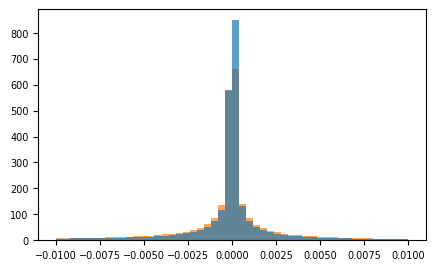

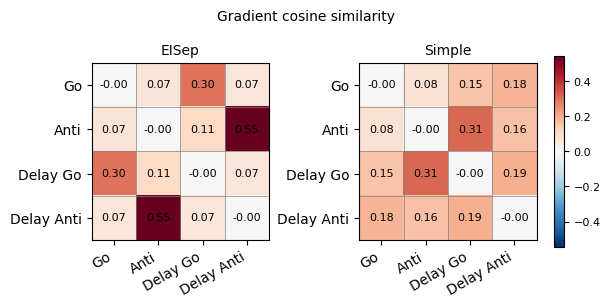

./output/continual_learning_gradient_alignment_reorder_old/gradient_cos_similarity_comparison.png


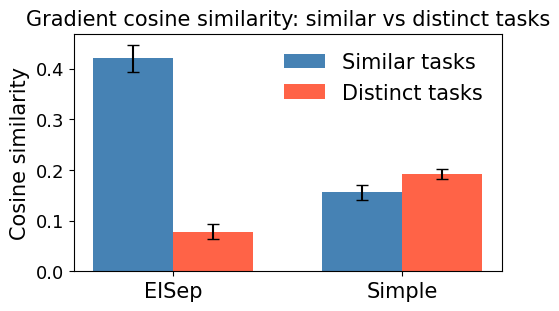

In [7]:
from net.common import savefig

model_names = ['eisep', 'simple']
legend_names = ['EISep', 'Simple']
model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
task_ids = ["go", "anti", "dlygo", "dlyanti"]
# task_names = ['Go', 'Delay Go', 'Anti', 'Delay Anti']
# task_ids = ['go', 'dlygo', 'anti', 'dlyanti']
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
infos = [pkl.load(open(path, 'rb')) for path in paths]
grad_direction_logs = [info['grad_direction_log_all'] for info in infos]


data1 = grad_direction_logs[0].flatten()
data2 = grad_direction_logs[1].flatten()
fig, ax = plt.subplots(1,1,figsize=(5,3))
ax.hist(data1, bins=50, density=True, color='C1', alpha=0.7, range=(-0.01,0.01))
ax.hist(data2, bins=50, density=True, color='C0', alpha=0.7, range=(-0.01,0.01))

cosine_sim_all = np.zeros((len(grad_direction_logs), len(envs), len(envs)))

fig, ax = plt.subplots(1, 2, figsize=(6, 3), constrained_layout=True)
similar_task_mask = np.zeros((len(envs), len(envs)))
mask_idxs = [[0,2], [1,3], [2,0], [3,1]]
for r, c in mask_idxs:
    similar_task_mask[r,c] = 1
print(similar_task_mask)
distinct_task_mask = 1 - np.eye(len(envs)) - similar_task_mask
distinct_indices = np.argwhere(distinct_task_mask == 1)
similar_pair_sims = np.zeros((len(grad_direction_logs), n_seed * repeat_times, len(mask_idxs)))
distinct_pair_sims = np.zeros((len(grad_direction_logs), n_seed * repeat_times, int(distinct_task_mask.sum())))


for i in range(len(grad_direction_logs)):
    # shape: (n_seed, repeat_times, n_task, hidden_size^2)
    G = grad_direction_logs[i].reshape(n_seed * repeat_times, len(envs), hidden_size**2)
    print('pos ratio',np.where(G>0,1,0).mean())
    cosine_matrix = np.zeros((n_seed * repeat_times, len(envs), len(envs)))
    for j in range(n_seed * repeat_times):
        g = G[j]  # (n_task, hidden_size^2)，已经归一化过
        cosine_matrix[j] = g @ g.T  # 归一化向量的内积即余弦相似度

        for k, (r, c) in enumerate(mask_idxs):
            similar_pair_sims[i, j, k] = cosine_matrix[j, r, c]
        for k, (r, c) in enumerate(distinct_indices):
            distinct_pair_sims[i, j, k] = cosine_matrix[j, r, c]

    # 减去对角线（自身相似度=1，不含信息）
    cosine_sim_all[i] = np.nanmean(cosine_matrix, axis=0) - np.eye(len(envs))



vmax = np.abs(cosine_sim_all).max()
vmin = -vmax

im = None

fontsize = 10
for i in range(len(grad_direction_logs)):
    im = ax[i].imshow(
        cosine_sim_all[i],
        vmin=vmin,
        vmax=vmax,
        cmap="RdBu_r",
        aspect="equal"
    )

    ax[i].set_xticks(range(len(envs)))
    ax[i].set_yticks(range(len(envs)))
    ax[i].set_xticklabels(task_names, rotation=30, ha="right", fontsize=fontsize)
    ax[i].set_yticklabels(task_names, fontsize=fontsize)

    ax[i].set_xticks(np.arange(len(envs) + 1) - 0.5, minor=True)
    ax[i].set_yticks(np.arange(len(envs) + 1) - 0.5, minor=True)
    ax[i].grid(which="minor", color="gray", linewidth=0.5)
    ax[i].tick_params(which="minor", bottom=False, left=False)

    ax[i].set_title(legend_names[i], fontsize=fontsize)

    for x in range(len(envs)):
        for y in range(len(envs)):
            ax[i].text(
                y, x,
                f"{cosine_sim_all[i, x, y]:.2f}",
                ha="center", va="center",
                fontsize=fontsize-2
            )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, shrink=0.8)
cbar.ax.tick_params(labelsize=fontsize-2)
# cbar.set_label("Gradient cosine similarity", fontsize=fontsize)
fig.suptitle("Gradient cosine similarity", fontsize=fontsize)
savefig('./output/continual_learning_gradient_alignment_reorder_old/gradient_cos_similarity.png')
plt.show()


fontsize = 15

similar_mean = similar_pair_sims.mean(axis=(1, 2))   # (n_model,)
similar_sem  = similar_pair_sims.std(axis=(1, 2)) / np.sqrt(n_seed * repeat_times * len(mask_idxs))

distinct_mean = distinct_pair_sims.mean(axis=(1, 2))  # (n_model,)
distinct_sem  = distinct_pair_sims.std(axis=(1, 2)) / np.sqrt(n_seed * repeat_times * len(distinct_indices))
fig, ax = plt.subplots(1, 1, figsize=(5, 3), constrained_layout=True)

x = np.arange(len(grad_direction_logs))
width = 0.35

bars1 = ax.bar(x - width/2, similar_mean, width, yerr=similar_sem,
               capsize=4, label='Similar tasks', color='steelblue')
bars2 = ax.bar(x + width/2, distinct_mean, width, yerr=distinct_sem,
               capsize=4, label='Distinct tasks', color='tomato')

ax.set_xticks(x)
ax.set_xticklabels(legend_names, fontsize=fontsize)
ax.set_ylabel('Cosine similarity', fontsize=fontsize)
ax.set_title('Gradient cosine similarity: similar vs distinct tasks', fontsize=fontsize)
ax.legend(frameon=False, fontsize=fontsize)
# ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
ax.tick_params(labelsize=fontsize-2, axis='y')
savefig('./output/continual_learning_gradient_alignment_reorder_old/gradient_cos_similarity_comparison.png')
plt.show()

In [8]:
from net.common import init_model
import pickle as pkl
model_names = ['eisep', 'simple']
legend_names = ['EISep', 'Simple']
model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
task_ids = ["go", "anti", "dlygo", "dlyanti"]
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
# model_names = ['eisep', 'simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# legend_names = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00', '#009E73']

lrs = [best_lr_dict[model_name] for model_name in model_names]
paths = [f'./result/continual_learning_gradient_alignment_reorder_old/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]
for i in range(len(paths)):
    print(paths[i])
infos = [pkl.load(open(path, 'rb')) for path in paths]
delta_W_logs = [info['delta_W_log_all'] for info in infos]
env_vecs = np.eye(len(envs))
performances_before = np.zeros((len(paths), n_seed, len(envs)))
performances_after = np.zeros((len(paths), n_seed, len(envs)))

def test_using_weight(env, net, env_vec, weight):
    perf = 0
    num_trial = 200
    net.eval()
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # Add batch axis
        ob = np.concatenate([ob, env_vec.reshape(1,1,-1).repeat(ob.shape[0], 0).repeat(ob.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net.forward_using_weight(inputs, weight)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += gt[-1] == action_pred[-1, 0]
    perf /= num_trial
    return perf
def test(env, net, env_vec):
    perf = 0
    num_trial = 200
    net.eval()
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # Add batch axis
        ob = np.concatenate([ob, env_vec.reshape(1,1,-1).repeat(ob.shape[0], 0).repeat(ob.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += gt[-1] == action_pred[-1, 0]
    perf /= num_trial
    return perf

for i in range(len(paths)):
    print(model_names[i])
    for j in range(n_seed):
        print('Seed:', j)
        np.random.seed(j)
        torch.manual_seed(j)
        net = init_model(
            ob_size=ob_size + len(envs),
            hidden_size=hidden_size,
            act_size=act_size,
            model_name=model_names[i]
        ).to(device)
        print(len(infos), len(infos[i]['net_state_dicts']), len(infos[i]['net_state_dicts'][j]), len(infos[i]['net_state_dicts'][j][-1]))
        net.load_state_dict(infos[i]['net_state_dicts'][j][-1][0]) # j-th seed, last round, Go task
        for k, env_test in enumerate(envs):
            performances_before[i, j, k] = test_using_weight(env_test, net, env_vecs[k], net.get_actual_weight())
        Y = delta_W_logs[i][j].mean(0)
        assert Y.shape == (len(envs), hidden_size, hidden_size)
        delta_weight = torch.FloatTensor(Y[-1]).to(device)
        transfer_weight = net.get_actual_weight() + delta_weight # Go + (Delay Anti - Delay Go)
        for k, env_test in enumerate(envs):
            performances_after[i, j, k] = test_using_weight(env_test, net, env_vecs[k], transfer_weight)
            # performances_after[i,j,k] = test(env_test, net, env_vecs[k])


./result/continual_learning_gradient_alignment_reorder_old/lr0.01_eisep_info.pkl
./result/continual_learning_gradient_alignment_reorder_old/lr0.005_simple_info.pkl
eisep
Seed: 0
Using UnFixed EISep RNN
2 5 10 4


KeyboardInterrupt: 

In [ ]:
w1 = infos[0]['net_state_dicts'][0][-1][-1]['lstm.Wrec_free']
w2 = infos[0]['net_state_dicts'][0][-1][0]['lstm.Wrec_free']
print(torch.linalg.norm(w2-w1))

tensor(2.2727, device='cuda:0')


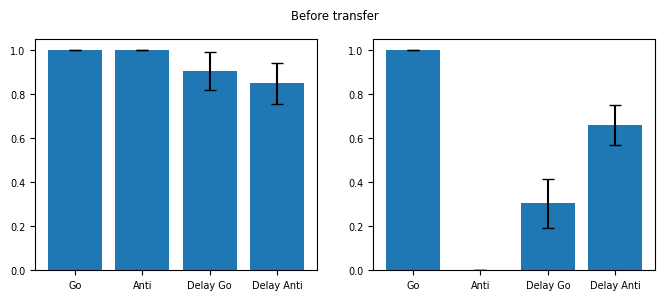

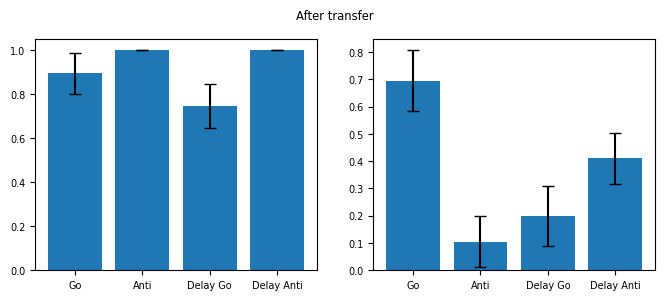

In [ ]:

fig, ax = plt.subplots(1,2, figsize=(8,3))
for i in range(len(paths)):
    ax[i].bar(np.arange(len(envs)), performances_before[i].mean(0), yerr=performances_before[i].std(0)/np.sqrt(n_seed), capsize=4)
    ax[i].set_xticks(np.arange(len(envs)), task_names)
fig.suptitle('Before transfer')
plt.show()


fig, ax = plt.subplots(1,2, figsize=(8,3))
for i in range(len(paths)):
    ax[i].bar(np.arange(len(envs)), performances_after[i].mean(0), yerr=performances_after[i].std(0)/np.sqrt(n_seed), capsize=4)
    ax[i].set_xticks(np.arange(len(envs)), task_names)
fig.suptitle('After transfer')
plt.show()

In [ ]:
# alphas = np.linspace(0,14,2)
alphas = np.arange(0,14,2)
# transfer_weights = np.zeros((len))
print(alphas)
performances_all = np.zeros((len(paths), n_seed, len(alphas), len(envs)))
for i in range(len(paths)):
    print(model_names[i])
    for j in range(n_seed):
        print('Seed:', j)
        np.random.seed(j)
        torch.manual_seed(j)
        net = init_model(
            ob_size=ob_size + len(envs),
            hidden_size=hidden_size,
            act_size=act_size,
            model_name=model_names[i]
        ).to(device)
        print(len(infos), len(infos[i]['net_state_dicts']), len(infos[i]['net_state_dicts'][j]), len(infos[i]['net_state_dicts'][j][-1]))
        net.load_state_dict(infos[i]['net_state_dicts'][j][-1][0]) # j-th seed, last round, Go task
        # Y = delta_W_logs[i][j].mean(0)
        Y = delta_W_logs[i][j]  # shape: (repeat_times, 4, H, H)
        Y_norm = Y / (np.linalg.norm(Y.reshape(repeat_times, len(envs), -1), axis=-1, keepdims=True).reshape(repeat_times, len(envs), 1, 1) + 1e-8)
        delta_weight = torch.FloatTensor(Y_norm.mean(0)[-1]).to(device)  # 只保留方向，去掉幅度差异
        # assert Y.shape == (len(envs), hidden_size, hidden_size)
        # delta_weight = torch.FloatTensor(Y[-1]).to(device)
        for m, alpha in enumerate(alphas):
            print('alpha:', alpha)

            transfer_weight = net.get_actual_weight() + delta_weight * alpha # Go + (Delay Anti - Delay Go)
            for k, env_test in enumerate(envs):
                performances_all[i, j, m, k] = test_using_weight(env_test, net, env_vecs[k], transfer_weight)

[ 0  2  4  6  8 10 12]
eisep
Seed: 0
Using UnFixed EISep RNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 1
Using UnFixed EISep RNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 2
Using UnFixed EISep RNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 3
Using UnFixed EISep RNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 4
Using UnFixed EISep RNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
simple
Seed: 0
Using simpleRNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 1
Using simpleRNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 2
Using simpleRNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 3
Using simpleRNN
2 5 10 4
alpha: 0
alpha: 2
alpha: 4
alpha: 6
alpha: 8
alpha: 10
alpha: 12
Seed: 4
Using simpleRNN
2 5 10 4
alpha: 0


./output/continual_learning_gradient_alignment_reorder_old/weight_transfer.png


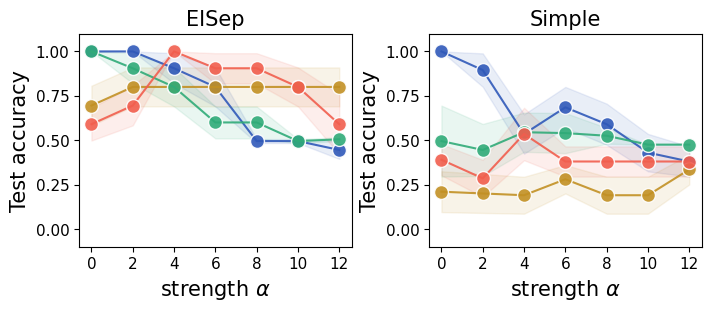

In [ ]:
legend_names = ['EISep', 'Simple']
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
task_colors = [
    "#3059B9",  # Group 1 - blue (darker)
    "#C29024",  # Group 2 - orange (darker)
    "#30AB78",  # Group 1 - blue (lighter)
    "#F15E4E",  # Group 2 - orange (lighter)
]
fontsize = 15
fig, ax = plt.subplots(1,2,figsize=(7,3), constrained_layout=True)
mean_performance = performances_all.mean(1)
ste_performance = performances_all.std(1)/np.sqrt(n_seed)
for i in range(len(paths)):
    for j in range(len(envs)):
        ax[i].plot(alphas, mean_performance[i,...,j], label=task_names[j], color=task_colors[j], alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10)
        ax[i].fill_between(alphas, mean_performance[i,...,j] - ste_performance[i,...,j], mean_performance[i,...,j] + ste_performance[i,...,j], alpha=0.1, color=task_colors[j])
        ax[i].set_ylim(-0.1,1.1)
    # ax[i].legend(fontsize=fontsize-2)
    ax[i].set_title(legend_names[i], fontsize=fontsize)
    ax[i].tick_params(labelsize=fontsize-4, axis='y')
    ax[i].tick_params(labelsize=fontsize-4, axis='x')
    ax[i].set_xticks(alphas)
    ax[i].set_xlabel(r'strength $\alpha$', fontsize=fontsize)
    ax[i].set_ylabel('Test accuracy', fontsize=fontsize)
# for j in range(len(envs)):
#     ax[-1].plot(0,0,label=task_names[j], color=task_colors[j], alpha=0.9,
#                    marker='o', markeredgecolor='white', markeredgewidth=1, markersize=8)
# ax[-1].legend(fontsize=fontsize-2, loc='center left', framealpha=1, shadow=True, markerscale=1)
# ax[-1].axis('off')
savefig('./output/continual_learning_gradient_alignment_reorder_old/weight_transfer.png')

plt.show()

./output/continual_learning_gradient_alignment_reorder_old/task_summary_legend.png


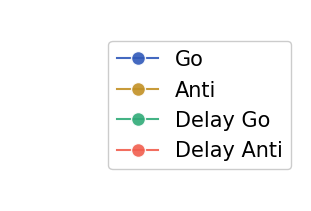

In [15]:
legend_names = ['EISep', 'Simple']
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
task_colors = [
    "#3059B9",  # Group 1 - blue (darker)
    "#C29024",  # Group 2 - orange (darker)
    "#30AB78",  # Group 1 - blue (lighter)
    "#F15E4E",  # Group 2 - orange (lighter)
]
fig, ax = plt.subplots(1,1, figsize=(3,2), constrained_layout=True)
for i in range(len(task_names)):
    ax.plot(0, 0, label=task_names[i], color=task_colors[i], alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10)
ax.legend(ncol=1, fontsize=fontsize, loc='center right', framealpha=1, shadow=False, markerscale=1)
ax.axis('off')
savefig('./output/continual_learning_gradient_alignment_reorder_old/task_summary_legend.png')

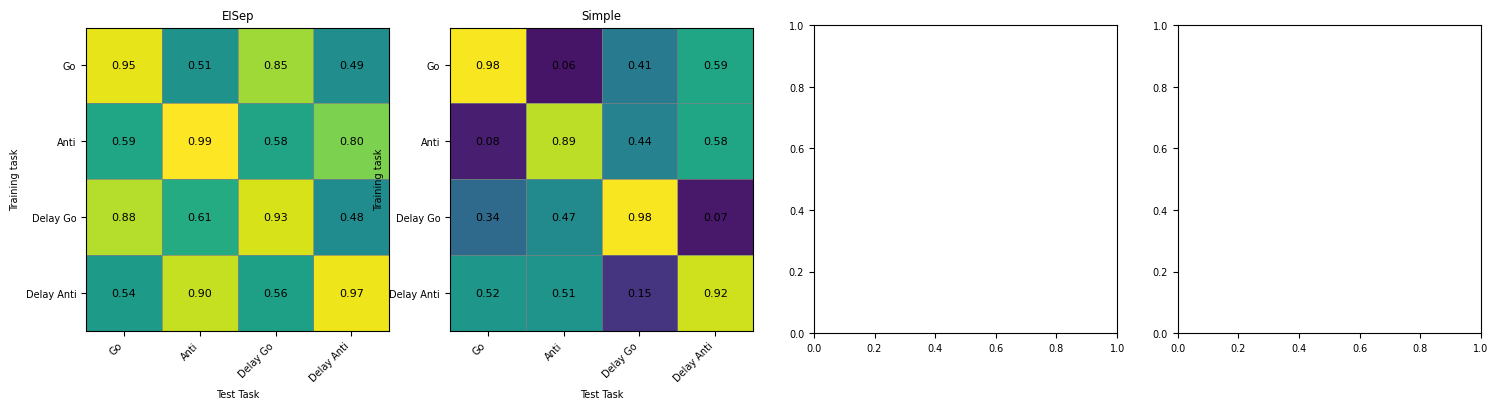

In [ ]:
test_perf_matrix = np.array([x.mean((0,1)) for x in test_perfs])
vmax = test_perf_matrix.max()
vmin = 0
fig, ax = plt.subplots(len(infos)//4+1,4,figsize=(18, 4*(len(infos)//4+1)))
ax = ax.flatten()
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
for i in range(len(infos)):
    ax[i].imshow(test_perf_matrix[i], vmax=vmax, vmin=vmin, cmap='viridis')

    ax[i].set_xticks(range(len(envs)))
    ax[i].set_yticks(range(len(envs)))
    ax[i].set_xticklabels(task_names, rotation=45, ha="right")
    ax[i].set_yticklabels(task_names)

    # grid between cells
    ax[i].set_xticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].set_yticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].grid(which="minor", color="gray", linewidth=0.5)
    ax[i].tick_params(which="minor", bottom=False, left=False)
    ax[i].set_title(legend_names[i])
    ax[i].set_xlabel('Test Task')
    ax[i].set_ylabel('Training task')
    for x in range(len(envs)):
        for y in range(len(envs)):
            ax[i].text(
                y, x,
                f"{test_perf_matrix[i,x,y]:.2f}",
                ha="center", va="center",
                fontsize=8
            )
plt.show()

./result/continual_learning_gradient_alignment_reorder/lr0.01_eisep_info.pkl
./result/continual_learning_gradient_alignment_reorder/lr0.005_simple_info.pkl
(5, 10, 4, 64, 64)
./output/continual_learning_gradient_alignment_reorder_old/weight_update.png


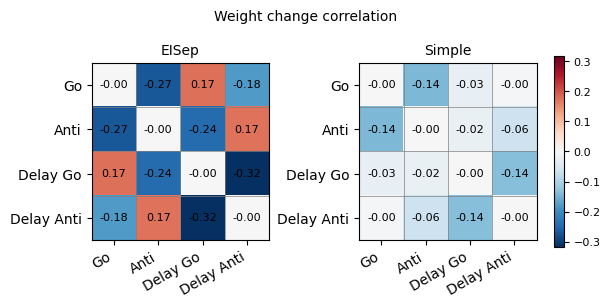

In [ ]:
from tkinter import font


model_names = ['eisep', 'simple']
legend_names = ['EISep', 'Simple']
model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
# model_names = ['eisep', 'simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# legend_names = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00', '#009E73']

lrs = [best_lr_dict[model_name] for model_name in model_names]
paths = [f'./result/continual_learning_gradient_alignment_reorder/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]
for i in range(len(paths)):
    print(paths[i])
infos = [pkl.load(open(path, 'rb')) for path in paths]
delta_W_logs = [info['delta_W_log_all'] for info in infos]
print(delta_W_logs[0].shape)
corr_average_all = np.zeros((len(delta_W_logs), len(envs), len(envs)))

fig, ax = plt.subplots(1, 2, figsize=(6,3), constrained_layout=True)
fontsize = 10
for i in range(len(delta_W_logs)):
    delta_W_log = delta_W_logs[i].reshape(n_seed * repeat_times, len(envs), hidden_size**2)
    corr_matrix = np.zeros((n_seed * repeat_times, len(envs), len(envs)))

    for j in range(n_seed * repeat_times):
        # corr_matrix[j] = np.corrcoef(delta_W_log[j])
        # corr_matrix[j] = delta_W_log[j]@delta_W_log[j].T
        d = delta_W_log[j]  # (n_task, hidden_size^2)
        # 归一化每个任务的delta_W向量
        norms = np.linalg.norm(d, axis=-1, keepdims=True)  # (n_task, 1)
        d_normalized = d / (norms + 1e-8)
        # 归一化后的内积即余弦相似度
        corr_matrix[j] = d_normalized @ d_normalized.T

    corr_average_all[i] = np.nanmean(corr_matrix, 0) - np.eye(len(envs))

# symmetric range around zero (better for correlation matrices)
vmax = np.abs(corr_average_all).max()
vmin = -vmax

im = None
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
for i in range(len(delta_W_logs)):
    im = ax[i].imshow(
        corr_average_all[i],
        vmin=vmin,
        vmax=vmax,
        cmap="RdBu_r",
        aspect="equal"
    )

    # ticks
    ax[i].set_xticks(range(len(envs)))
    ax[i].set_yticks(range(len(envs)))
    ax[i].set_xticklabels(task_names, rotation=30, ha="right", fontsize=fontsize)
    ax[i].set_yticklabels(task_names, fontsize=fontsize)

    # grid between cells
    ax[i].set_xticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].set_yticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].grid(which="minor", color="gray", linewidth=0.5)
    ax[i].tick_params(which="minor", bottom=False, left=False, labelsize=fontsize)
    ax[i].set_title(legend_names[i], fontsize=fontsize)
    for x in range(len(envs)):
        for y in range(len(envs)):
            ax[i].text(
                y, x,
                f"{corr_average_all[i,x,y]:.2f}",
                ha="center", va="center",
                fontsize=fontsize-2
            )

# shared colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, shrink=0.8)
cbar.ax.tick_params(labelsize=fontsize-2)
fig.suptitle("Weight change correlation", fontsize=fontsize)
savefig('./output/continual_learning_gradient_alignment_reorder_old/weight_update.png')
# plt.tight_layout()
plt.show()

In [ ]:
# for i in range(len(delta_W_logs)):
#     delta_W_log_single_model = delta_W_logs[i].reshape(n_seed * repeat_times, len(envs), hidden_size**2)
#     evr_single_model = np.zeros((n_seed * repeat_times, len(envs)))
#     r2_single_model = np.zeros((n_seed * repeat_times, ))
#     for j in range(n_seed * repeat_times):
#         delta_W_all = delta_W_log_single_model[j]
#         assert delta_W_all.shape == (len(envs), hidden_size**2)
#         delta_W_all = delta_W_all - delta_W_all.mean(axis=0, keepdims=True)
#         try:
#             u, s, vt = np.linalg.svd(delta_W_all)
#         except:
#             print(delta_W_all)
#             evr_single_model[j] = np.nan
#             r2_single_model[j] = np.nan
#             continue
#         explained_variance_ratio = s**2/np.sum(s**2)
#         # print('evr:', explained_variance_ratio)
#         evr_single_model[j] = explained_variance_ratio

#         X = np.array([[1,-1,1],[1,1,1],[-1,-1,1],[-1,1,1]]) # [if go, if delay, bias]
#         B, residuals, rank, s = np.linalg.lstsq(X, delta_W_all, rcond=None)
#         Y_hat = X @ B
#         ss_res = np.sum((delta_W_all - Y_hat)**2)
#         ss_tot = np.sum((delta_W_all - delta_W_all.mean(axis=0))**2)
#         R2 = 1 - ss_res/ss_tot
#         # print("R2:", R2)
#         r2_single_model[j] = R2
#     print('average:', np.nanmean(evr_single_model,0), np.nanstd(evr_single_model,0))
#     print('r2:', np.nanmean(r2_single_model), np.nanstd(r2_single_model))

model 0
average evr: [5.91575749e-01 2.58898554e-01 1.49525697e-01 5.35476237e-32] [9.51460762e-02 6.69774974e-02 4.65401097e-02 5.61453277e-32]
r2: 0.7193025285299656 0.06928742630031647
model 1
average evr: [5.11345460e-01 3.11910720e-01 1.76743819e-01 3.19548575e-31] [7.58475623e-02 5.30467262e-02 4.85063486e-02 3.19870336e-31]
r2: 0.6383151384084832 0.041594607085868374


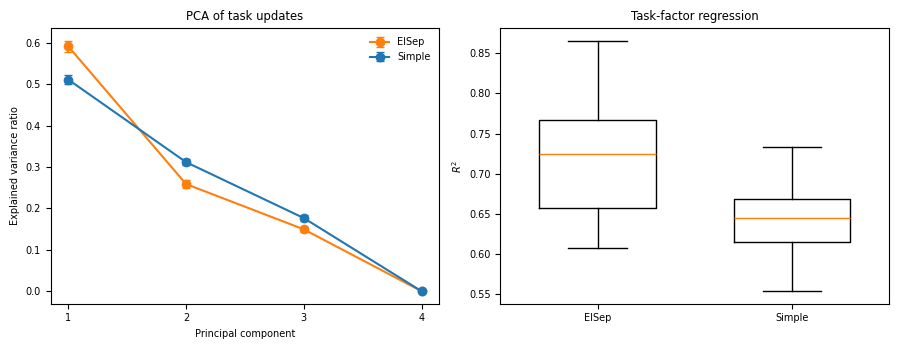

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# settings
# --------------------------------------------------
legend_names = ['EISep', 'Simple']   # example
colors = ['C1', 'C0']

X = np.array([
    [1,  1, -1],   # Go
    [1,  1,  1],   # DelayGo
    [1, -1, -1],   # Anti
    [1, -1,  1],   # DelayAnti
], dtype=float)  # columns: [bias, rule, memory]

# precompute pseudo-inverse for regression
X_pinv = np.linalg.pinv(X)   # shape: (3, 4)

all_evr = []
all_r2 = []

for i in range(len(delta_W_logs)):
    # ----------------------------------------------
    # reshape to: (samples, tasks, parameters)
    # ----------------------------------------------
    Y = delta_W_logs[i].reshape(
        n_seed * repeat_times,
        len(envs),
        hidden_size**2
    )

    assert Y.shape[1] == 4, "This code assumes 4 tasks: Go, DelayGo, Anti, DelayAnti."
    valid_mask = ~np.isnan(Y).any(axis=(1,2))
    Y = Y[valid_mask]
    # ----------------------------------------------
    # center across tasks for each parameter dimension
    # Y_centered: (samples, tasks, parameters)
    # ----------------------------------------------
    Y_centered = Y - Y.mean(axis=1, keepdims=True)

    # ----------------------------------------------
    # batched SVD over the last two dims
    # For each sample: (tasks, parameters)
    # S shape: (samples, min(tasks, parameters)) = (samples, 4)
    # ----------------------------------------------
    U, S, Vt = np.linalg.svd(Y_centered, full_matrices=False)

    # explained variance ratio
    # shape: (samples, 4)
    evr_single_model = (S**2) / np.sum(S**2, axis=1, keepdims=True)

    # ----------------------------------------------
    # batched regression:
    # want B such that Y_centered ≈ X @ B
    # X_pinv shape: (3, 4)
    # Y_centered shape: (samples, 4, parameters)
    #
    # einsum:
    #   B[s, a, p] = sum_t X_pinv[a, t] * Y_centered[s, t, p]
    # so B shape = (samples, 3, parameters)
    # ----------------------------------------------
    B = np.einsum('at,stp->sap', X_pinv, Y_centered)

    # reconstruct
    # Y_hat[s, t, p] = sum_a X[t, a] * B[s, a, p]
    # shape: (samples, 4, parameters)
    Y_hat = np.einsum('ta,sap->stp', X, B)

    # ----------------------------------------------
    # batched R^2
    # ss_res, ss_tot shape: (samples,)
    # ----------------------------------------------
    ss_res = np.sum((Y_centered - Y_hat)**2, axis=(1, 2))
    ss_tot = np.sum(Y_centered**2, axis=(1, 2))

    # avoid division-by-zero
    r2_single_model = np.full(ss_tot.shape, np.nan, dtype=float)
    valid = ss_tot > 0
    r2_single_model[valid] = 1 - ss_res[valid] / ss_tot[valid]

    all_evr.append(evr_single_model)
    all_r2.append(r2_single_model)

    print(f'model {i}')
    print('average evr:', np.nanmean(evr_single_model, axis=0), np.nanstd(evr_single_model, axis=0))
    print('r2:', np.nanmean(r2_single_model), np.nanstd(r2_single_model))


# --------------------------------------------------
# plotting
# --------------------------------------------------

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))

# ---------- left panel: EVR ----------
pcs = np.arange(1, len(envs) + 1)

for i in range(len(all_evr)):
    mean_evr = np.nanmean(all_evr[i], axis=0)
    std_evr  = np.nanstd(all_evr[i], axis=0)/np.sqrt(repeat_times*n_seed)

    ax[0].errorbar(
        pcs, mean_evr, yerr=std_evr,
        marker='o', capsize=3, label=legend_names[i],
        color=colors[i]
    )

ax[0].set_xlabel('Principal component')
ax[0].set_ylabel('Explained variance ratio')
ax[0].set_title('PCA of task updates')
ax[0].set_xticks(pcs)
ax[0].legend(frameon=False)

# ---------- right panel: R^2 ----------
box_data = [r[np.isfinite(r)] for r in all_r2]

ax[1].boxplot(box_data, tick_labels=legend_names, widths=0.6)
ax[1].set_ylabel(r'$R^2$')
ax[1].set_title('Task-factor regression')

plt.tight_layout()
plt.show()

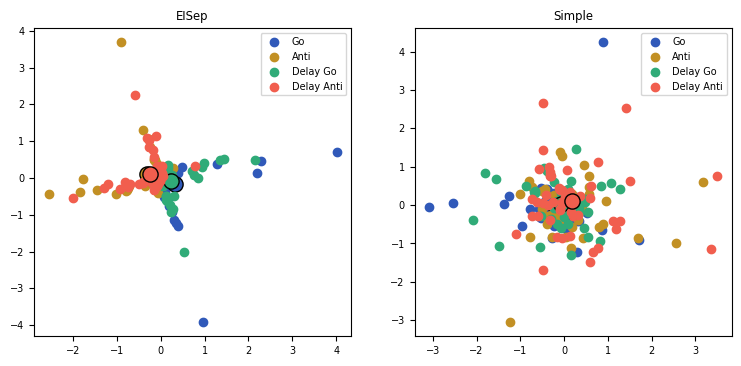

In [ ]:
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
fig, ax = plt.subplots(1,2,figsize=(9,4))
task_colors = [
    "#3059B9",  # Group 1 - blue (darker)
    
    "#C29024",  # Group 2 - orange (darker)
    "#30AB78",  # Group 1 - blue (lighter)

    "#F15E4E",  # Group 2 - orange (lighter)
]

task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]
model_names = ['EISep', 'Simple']
for i in range(len(delta_W_logs)):
    # ----------------------------------------------
    # reshape to: (samples, tasks, parameters)
    # ----------------------------------------------
    Y = delta_W_logs[i].reshape(
        n_seed * repeat_times,
        len(envs),
        hidden_size**2
    )

    assert Y.shape[1] == 4, "This code assumes 4 tasks: Go, DelayGo, Anti, DelayAnti."
    valid_mask = ~np.isnan(Y).any(axis=(1,2))
    Y = Y[valid_mask]
    Y_centered = Y - Y.mean(axis=1, keepdims=True)
    n_sample = Y_centered.shape[0]
    reduced_y = PCA(n_components=2).fit_transform(Y_centered.reshape(n_sample * len(envs), hidden_size**2)).reshape(n_sample, len(envs), 2)
    for j in range(len(task_colors)):
        ax[i].scatter(reduced_y[:,j,0], reduced_y[:,j,1], color=task_colors[j], label=task_names[j])
        mean_xy = reduced_y.mean(axis=0)  # shape: (4,2)
        ax[i].scatter(mean_xy[j,0], mean_xy[j,1], color=task_colors[j], s=120, edgecolor='k')
    ax[i].legend()
    ax[i].set_title(model_names[i])
plt.show()


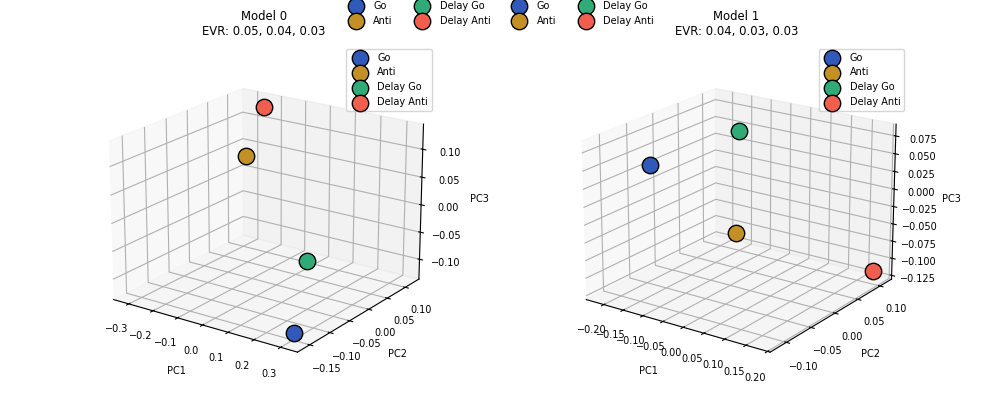

In [ ]:
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import numpy as np
%matplotlib widget
task_colors = [
    "#3059B9",  # Go

    "#C29024",  # Anti
    "#30AB78",  # DelayGo
    "#F15E4E",  # DelayAnti
]
task_names = ["Go", "Anti", "Delay Go", "Delay Anti"]

fig = plt.figure(figsize=(10, 4))

for i in range(len(delta_W_logs)):
    ax = fig.add_subplot(1, len(delta_W_logs), i + 1, projection='3d')

    # ----------------------------------------------
    # reshape to: (samples, tasks, parameters)
    # ----------------------------------------------
    Y = delta_W_logs[i].reshape(
        n_seed * repeat_times,
        len(envs),
        hidden_size**2
    )

    assert Y.shape[1] == 4, "This code assumes 4 tasks: Go, DelayGo, Anti, DelayAnti."

    # remove invalid samples
    valid_mask = ~np.isnan(Y).any(axis=(1, 2))
    Y = Y[valid_mask]

    # per-sample centering across tasks
    Y_centered = Y - Y.mean(axis=1, keepdims=True)

    n_sample = Y_centered.shape[0]

    # PCA to 3D
    Y_flat = Y_centered.reshape(n_sample * len(envs), hidden_size**2)
    pca = PCA(n_components=3)
    reduced_y = pca.fit_transform(Y_flat).reshape(n_sample, len(envs), 3)

    # task-wise mean in PCA space
    mean_xyz = reduced_y.mean(axis=0)  # shape: (4, 3)

    for j in range(len(task_colors)):
        # all samples
        # ax.scatter(
        #     reduced_y[:, j, 0],
        #     reduced_y[:, j, 1],
        #     reduced_y[:, j, 2],
        #     color=task_colors[j],
        #     alpha=0.25,
        #     s=18,
        #     label=task_names[j] if i == 0 else None
        # )

        # mean point
        ax.scatter(
            mean_xyz[j, 0],
            mean_xyz[j, 1],
            mean_xyz[j, 2],
            color=task_colors[j],
            s=140,
            edgecolor='k',
            linewidth=1.0,
            label = task_names[j]
        )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(f"Model {i}")

    # optional: show explained variance in title
    evr = pca.explained_variance_ratio_
    ax.set_title(
        f"Model {i}\n"
        f"EVR: {evr[0]:.2f}, {evr[1]:.2f}, {evr[2]:.2f}"
    )

    # optional: better viewing angle
    ax.view_init(elev=20, azim=-55)
    ax.legend()
fig.legend(loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()
%matplotlib inline

In [ ]:
def collect_hidden_states(env, net, env_vec, num_trial=100):
    """
    收集网络在某个任务上的隐层激活。
    返回 shape: (total_timesteps, hidden_size)
    """
    net.eval()
    all_hidden = []
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # (T, 1, ob_size)
        ob = np.concatenate(
            [ob, env_vec.reshape(1, 1, -1).repeat(ob.shape[0], 0).repeat(ob.shape[1], 1)],
            axis=-1
        )
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        with torch.no_grad():
            _, _, hidden = net(inputs)  # hidden: [(T, 1, hidden_size),...]
        all_hidden.append(hidden[0].squeeze(1).cpu().numpy())  # (T, hidden_size)
    return np.concatenate(all_hidden, axis=0)  # (total_T, hidden_size)
